
# DSC 106 Project 2: NYPD Civilian Complaints

### Proposition: Higher-ranking NYPD officers tend to have lower average substantiation rates for civilian allegations.


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
df = pd.read_csv("complaints/complaints.csv")

ranks = ["Police Officer", "Sergeant", "Lieutenant"]

df["substantiated"] = (
    df["board_disposition"]
    .str.startswith("Substantiated", na=False)
    .astype(int)
)

df_rank = df[df["rank_incident"].isin(ranks)].copy()

print(df_rank.shape)
df_rank.head()


(29744, 28)


,unique_mos_id,first_name,last_name,command_now,shield_no,complaint_id,month_received,year_received,month_closed,year_closed,...,complainant_ethnicity,complainant_gender,complainant_age_incident,fado_type,allegation,precinct,contact_reason,outcome_description,board_disposition,substantiated
0,10004,Jonathan,Ruiz,078 PCT,8409,42835,7,2019,5,2020,...,Black,Female,38.0,Abuse of Authority,Failure to provide RTKA card,78.0,Report-domestic dispute,No arrest made or summons issued,Substantiated (Command Lvl Instructions),1
1,10007,John,Sears,078 PCT,5952,24601,11,2011,8,2012,...,Black,Male,26.0,Discourtesy,Action,67.0,Moving violation,Moving violation summons issued,Substantiated (Charges),1
2,10007,John,Sears,078 PCT,5952,24601,11,2011,8,2012,...,Black,Male,26.0,Offensive Language,Race,67.0,Moving violation,Moving violation summons issued,Substantiated (Charges),1
3,10007,John,Sears,078 PCT,5952,26146,7,2012,9,2013,...,Black,Male,45.0,Abuse of Authority,Question,67.0,PD suspected C/V of violation/crime - street,No arrest made or summons issued,Substantiated (Charges),1
4,10009,Noemi,Sierra,078 PCT,24058,40253,8,2018,2,2019,...,NaN,NaN,16.0,Force,Physical force,67.0,Report-dispute,Arrest - other violation/crime,Substantiated (Command Discipline A),1



### Visualization 1: Supporting the Proposition


In [52]:
heatmap_data = (
    df_rank
    .groupby(["unique_mos_id", "rank_incident", "fado_type"])["substantiated"]
    .mean()
    .reset_index(name="officer_rate")
    .groupby(["fado_type", "rank_incident"])["officer_rate"]
    .mean()
    .mul(100)
    .unstack()
    .reindex(columns=ranks)
)

heatmap_data.round(1)

rank_incident,Police Officer,Sergeant,Lieutenant
fado_type,,,
Abuse of Authority,42.2,34.2,27.6
Discourtesy,26.8,18.5,18.3
Force,14.6,10.2,8.8
Offensive Language,18.8,14.7,6.7


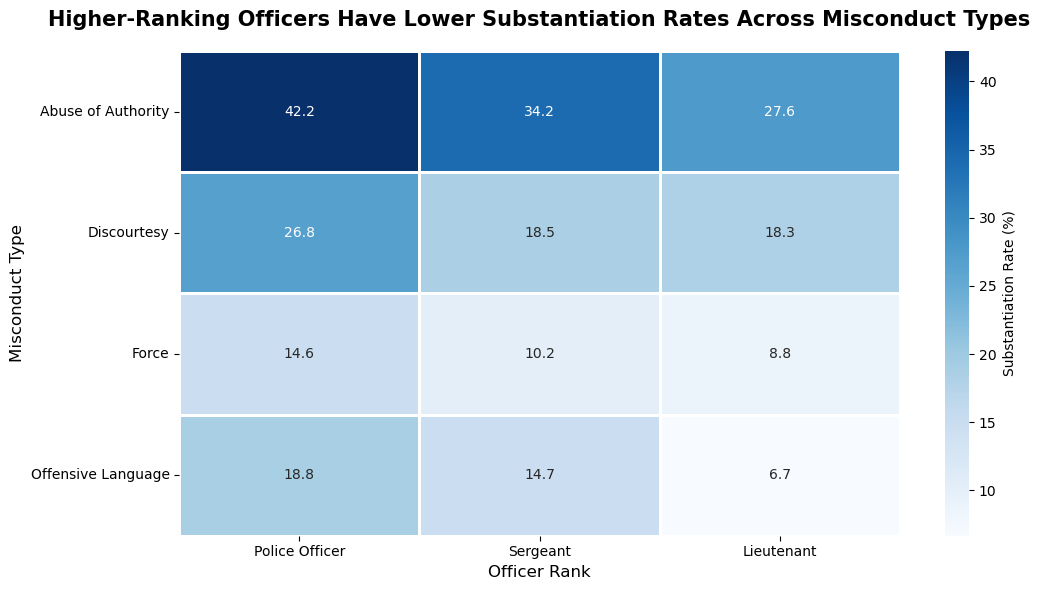

In [53]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Substantiation Rate (%)"}
)

plt.title(
    "Higher-Ranking Officers Have Lower Substantiation Rates Across Misconduct Types",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Officer Rank", fontsize=12)
plt.ylabel("Misconduct Type", fontsize=12)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### Interpretation

The heatmap generally supports the proposition that higher-ranking NYPD officers have lower substantiation rates. Across the four misconduct categories, Police Officers have higher substantiation rates than Sergeants and Lieutenants. This suggests that the negative relationship between rank and substantiation is not limited to one type of misconduct.



### Visualization 2: Opposing the Proposition

**Question:** Does the relationship between rank and substantiation still hold among officers with frequent allegations?

This visualization focuses on officers who received at least 10 allegations while holding a particular rank.


In [49]:
df_repeat = (
    df_rank.groupby(["unique_mos_id", "rank_incident"])
    .agg(
        allegations=("substantiated", "size"),
        rate=("substantiated", "mean")
    )
    .reset_index()
)

df_repeat["rate"] *= 100

subset = df_repeat[df_repeat["allegations"] >= 10]

opp_summary = (
    subset.groupby("rank_incident")
    .agg(
        mean_rate=("rate", "mean"),
        num_officers=("unique_mos_id", "nunique")
    )
    .reindex(ranks)
)

opp_summary.round(1)


,mean_rate,num_officers
rank_incident,,
Police Officer,18.9,711
Sergeant,19.5,204
Lieutenant,15.7,40


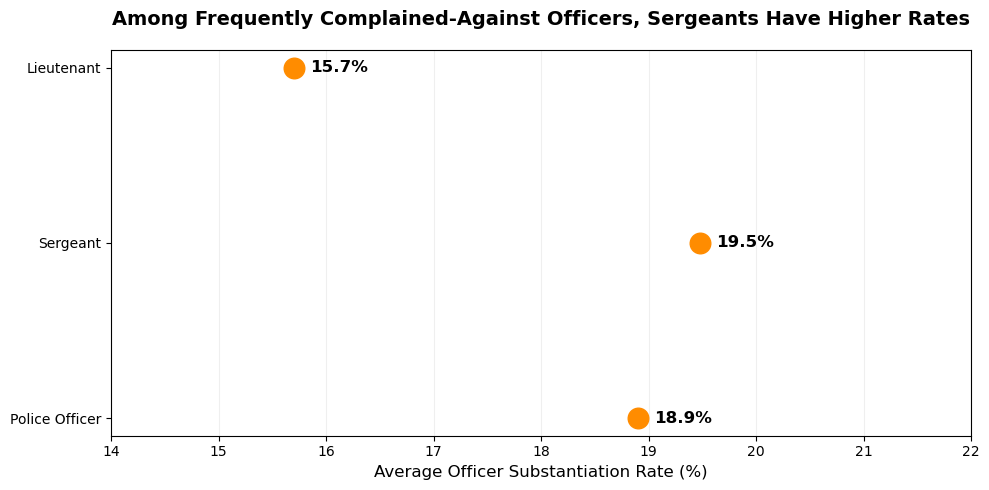

In [50]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    opp_summary["mean_rate"],
    opp_summary.index,
    s=220,
    color="darkorange",
    zorder=3
)

for rank, row in opp_summary.iterrows():
    ax.text(
        row["mean_rate"] + 0.15,
        rank,
        f'{row["mean_rate"]:.1f}%',
        va="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Among Frequently Complained-Against Officers, Sergeants Have Higher Rates",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Average Officer Substantiation Rate (%)",
    fontsize=12
)

ax.set_ylabel("")
ax.set_xlim(14, 22)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### Interpretation

Among officers with at least 10 allegations at a given rank, Sergeants have a slightly higher average substantiation rate (19.5%) than Police Officers (18.9%). This partially oppose the proposition because the substantiation rate does not consistently decrease with increasing rank.
